# 06 — End-to-End Lorenz-96 Pipeline

This notebook demonstrates the full data-preprocessing and training pipeline
for 4DVarNet on the Lorenz-96 attractor, using the functional utilities in
`vardax._src.utils`.

**Pipeline overview:**
1. Simulate L96 with Diffrax (N=40, F=8)
2. Build an xarray Dataset and extract patches
3. Add observation masks and Gaussian noise
4. Train/test split in time (before patch extraction) and standardize
5. Visualize the L96 attractor (`plot_l96_grid`)
6. Train `FourDVarNet1D` (default bilinear autoencoder prior)
7. Evaluate and visualize reconstruction

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import vardax
from vardax import (
    Batch1D,
    FourDVarNet1D,
    simulate_lorenz96,
    plot_l96_grid,
    plot_l96_trajectories,
    plot_reconstruction_comparison,
)
from vardax._src.utils.patches import trajectory_to_xr_dataset, extract_patches
from vardax._src.utils.masks import regular_mask
from vardax._src.utils.noise import add_gaussian_noise
from vardax._src.utils.preprocessing import xr_to_batch1d
from vardax._src.utils.standardize import (
    compute_scaler_params,
    apply_standardization,
    inverse_standardization,
)

## 1. Simulate Lorenz-96

In [2]:
key = jax.random.PRNGKey(0)
N = 40
time_coords, states = simulate_lorenz96(
    key,
    n_sites=N,
    forcing=8.0,
    dt=0.01,
    n_steps=5000,
    n_burn_in=1000,
)
print(f"states shape: {states.shape}, time range: [{time_coords[0]:.2f}, {time_coords[-1]:.2f}]")

states shape: (5001, 40), time range: [0.00, 50.00]


## 2. Build xarray Dataset and Extract Patches

In [3]:
ds = trajectory_to_xr_dataset(states, time_coords)
# Split the trajectory in time *before* cutting windows, so no window
# straddles the boundary: windows drawn at random from one trajectory and
# split afterwards would leak test timesteps into the training set.
n_time = ds.sizes["time"]
ds_train = extract_patches(ds.isel(time=slice(0, int(0.8 * n_time))), n_patches=160, n_timesteps=20, seed=42)
ds_test = extract_patches(ds.isel(time=slice(int(0.8 * n_time), None)), n_patches=40, n_timesteps=20, seed=43)
print(ds_train)

<xarray.Dataset> Size: 514kB
Dimensions:  (patch: 160, time: 20, feature: 40)
Coordinates:
  * patch    (patch) int64 1kB 0 1 2 3 4 5 6 7 ... 153 154 155 156 157 158 159
  * time     (time) int64 160B 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19
  * feature  (feature) <U3 480B 'x0' 'x1' 'x2' 'x3' ... 'x36' 'x37' 'x38' 'x39'
Data variables:
    state    (patch, time, feature) float32 512kB 5.577 5.981 ... 2.152 -2.802


## 3. Add Observation Masks and Gaussian Noise

In [4]:
ds_train = regular_mask(ds_train, variable="state", obs_interval=2)
ds_test = regular_mask(ds_test, variable="state", obs_interval=2)
ds_train = add_gaussian_noise(ds_train, variable="state", sigma=0.5, seed=0, name="obs")
ds_test = add_gaussian_noise(ds_test, variable="state", sigma=0.5, seed=1, name="obs")
print(ds_train)

<xarray.Dataset> Size: 2MB
Dimensions:  (patch: 160, time: 20, feature: 40)
Coordinates:
  * patch    (patch) int64 1kB 0 1 2 3 4 5 6 7 ... 153 154 155 156 157 158 159
  * time     (time) int64 160B 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19
  * feature  (feature) <U3 480B 'x0' 'x1' 'x2' 'x3' ... 'x36' 'x37' 'x38' 'x39'
Data variables:
    state    (patch, time, feature) float32 512kB 5.577 5.981 ... 2.152 -2.802
    mask     (patch, time, feature) float32 512kB 1.0 1.0 1.0 ... 0.0 0.0 0.0
    obs      (patch, time, feature) float32 512kB 5.64 5.915 ... 2.588 -4.045


## 4. Standardize

In [5]:
print(f"train patches: {ds_train.sizes['patch']}, test patches: {ds_test.sizes['patch']}")

mean, std = compute_scaler_params(ds_train, variable="state", mask_variable="mask")
print(f"mean={mean:.4f}, std={std:.4f}")

ds_train = apply_standardization(ds_train, variables=["state", "obs"], mean=mean, std=std)
ds_test = apply_standardization(ds_test, variables=["state", "obs"], mean=mean, std=std)

train patches: 160, test patches: 40
mean=2.3705, std=3.6421


## 5. Visualize the L96 Attractor

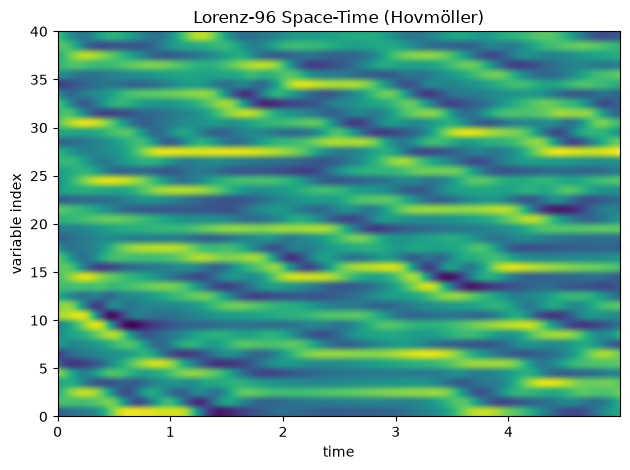

In [6]:
fig, ax = plot_l96_grid(states[:500], time_coords[:500])
ax.set_title("Lorenz-96 Space-Time (Hovmöller)")
plt.tight_layout()
plt.show()

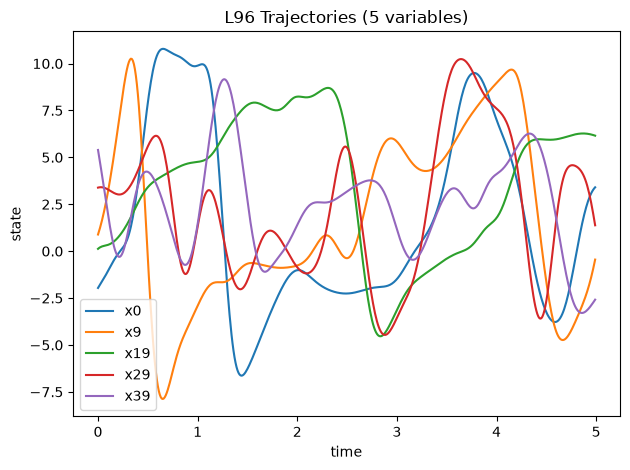

In [7]:
fig, ax = plot_l96_trajectories(states[:500], time_coords[:500], n_vars=5)
ax.set_title("L96 Trajectories (5 variables)")
plt.tight_layout()
plt.show()

## 6. Train FourDVarNet1D

`FourDVarNet1D` builds its own `BilinAEPrior1D` over the flattened
`(T, N)` window; the per-state `L96Prior` autoencoder targets the
`(B, N)` seam and is not used here.

In [8]:
# (NNX removed in Epic 0 — vardax is now equinox-native)

batch_train = xr_to_batch1d(ds_train, state_var="state", obs_var="obs", mask_var="mask")
batch_test = xr_to_batch1d(ds_test, state_var="state", obs_var="obs", mask_var="mask")
print(f"train: input={batch_train.input.shape}, mask={batch_train.mask.shape}, target={batch_train.target.shape}")

train: input=(160, 20, 40), mask=(160, 20, 40), target=(160, 20, 40)


In [9]:
_, T_dim, N_dim = batch_train.input.shape
model = FourDVarNet1D(
    state_dim=N_dim,
    n_time=T_dim,
    latent_dim=16,
    hidden_dim=32,
    n_solver_steps=5,
    key=jax.random.PRNGKey(1),
)

model, train_losses, _ = vardax.examples.fit_demo(
    model,
    [batch_train],
    n_epochs=5,
    lr=1e-3,
    verbose=True,
)
print("Final train loss:", train_losses[-1])

epoch 1/5 — train loss: 0.523741
epoch 2/5 — train loss: 0.497980
epoch 3/5 — train loss: 0.474440


epoch 4/5 — train loss: 0.452510
epoch 5/5 — train loss: 0.431813
Final train loss: 0.4318126440048218


## 7. Evaluate and Visualize Reconstruction

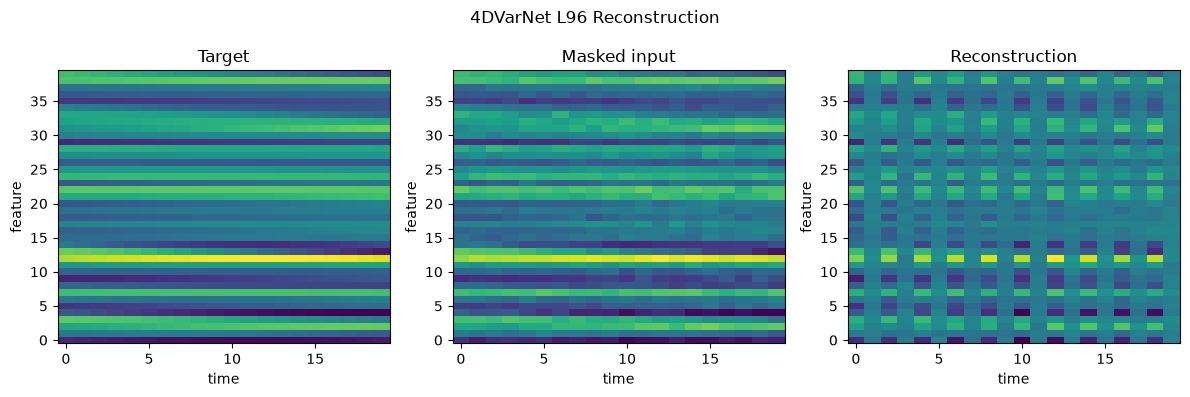

In [10]:
recon = model(batch_test)

target_np = jnp.array(batch_test.target)
input_np = jnp.array(batch_test.input)
recon_np = jnp.array(recon)

fig, axes = plot_reconstruction_comparison(target_np, input_np, recon_np, sample_idx=0)
plt.suptitle("4DVarNet L96 Reconstruction")
plt.tight_layout()
plt.show()